In [15]:
import psutil
print(psutil.cpu_count(logical=True))

4


In [16]:
!pip install scapy sdv torch

In [17]:
import os
import pandas as pd
import numpy as np
from scapy.all import *
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.manifold import TSNE
from pandas.plotting import autocorrelation_plot
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models
from sdv.single_table import CTGANSynthesizer
from sdv.metadata import SingleTableMetadata
import torch

In [18]:
# Load dataset which contains multiple attack types
full_df_path = '/kaggle/input/datasets/brenda101/farm-flow-dataset/Datasets/Farm-Flows.csv'
full_df = pd.read_csv(full_df_path)

print(full_df['traffic'].value_counts())

/tmp/ipykernel_58/2936157789.py:3: DtypeWarning: Columns (6,7,8) have mixed types. Specify dtype option on import or set low_memory=False.
  full_df = pd.read_csv(full_df_path)


traffic
TCP_Flood        381765
UDP_Flood        296553
HTTP_Flood       265025
MQTT_Flood       132506
Port_Scanning    126700
ICMP_Flood        76849
Normal            27458
Arp_Spoofing       2967
BotNet_DDOS          64
Name: count, dtype: int64


In [19]:
full_df.head(100)

,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,resp_bytes,conn_state,...,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,bwd_last_window_size,traffic,is_attack
0,192.168.1.13,37985,192.168.1.5,1883,tcp,mqtt,0.203465,151,32,OTH,...,0.0,0.0,0.0,0.0,0,0,0,0,Normal,0
1,192.168.1.4,51235,192.168.1.5,1880,tcp,http,0.013874,181,0,S1,...,0.0,0.0,0.0,0.0,2081,64048,1961,64048,Normal,0
2,192.168.1.4,63023,192.168.1.5,1880,tcp,-,0.000520,0,0,SF,...,0.0,0.0,0.0,0.0,2081,64856,1931,64856,Normal,0
3,192.168.1.9,57223,192.168.1.5,1883,tcp,mqtt,4.107098,250,150,OTH,...,0.0,0.0,0.0,0.0,2144,64240,2144,64065,Normal,0
4,192.168.1.11,50213,192.168.1.5,1883,tcp,mqtt,4.362811,250,150,OTH,...,0.0,0.0,0.0,0.0,2081,64856,1931,64856,Normal,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,192.168.1.13,37985,192.168.1.5,1883,tcp,mqtt,0.202905,151,32,OTH,...,0.0,0.0,0.0,0.0,1691,64856,1541,64856,Normal,0
96,192.168.1.11,50213,192.168.1.5,1883,tcp,mqtt,4.238546,250,150,OTH,...,0.0,0.0,0.0,0.0,1691,64856,1541,64856,Normal,0
97,192.168.1.11,50213,192.168.1.5,1883,tcp,mqtt,4.102940,250,150,OTH,...,0.0,0.0,0.0,0.0,0,0,0,0,Normal,0
98,192.168.1.6,60446,192.168.1.5,1883,tcp,mqtt,4.209213,250,150,OTH,...,0.0,0.0,0.0,0.0,1825,509,1825,509,Normal,0


Synthetic Data Generation

In [20]:
# Basic cleaning to ensure the Generator doesn't learn 'None' or '-'
full_df['service'] = full_df['service'].replace('-', 'unknown')
full_df['proto'] = full_df['proto'].astype(str)
full_df['conn_state'] = full_df['conn_state'].astype(str)


TARGET_COUNT = 250000
target_col = 'traffic'

If dataset used as is; 
PerformanceAlert: Using the CTGANSynthesizer on this data is not recommended. To model this data, CTGAN will generate a large number of columns.
Original Column Name     Est # of Columns (CTGAN)
id.orig_h                1
id.orig_p                11
id.resp_h                1
id.resp_p                1
proto                    1
service                  1
duration                 19163
orig_bytes               495
resp_bytes               2
local_orig               1
local_resp               1
missed_bytes             11
history                  16
orig_pkts                4
orig_ip_bytes            4
resp_pkts                5
resp_ip_bytes            8
tunnel_parents           1
flow_duration            11
fwd_pkts_tot             7
bwd_pkts_tot             7
fwd_data_pkts_tot        6
bwd_data_pkts_tot        5
fwd_pkts_per_sec         11
bwd_pkts_per_sec         11
flow_pkts_per_sec        11
down_up_ratio            11
fwd_header_size_tot      11
fwd_header_size_min      6
fwd_header_size_max      6
bwd_header_size_tot      11
bwd_header_size_min      7
bwd_header_size_max      7
flow_FIN_flag_count      5
flow_SYN_flag_count      5
flow_RST_flag_count      4
fwd_PSH_flag_count       4
bwd_PSH_flag_count       5
flow_ACK_flag_count      11
fwd_URG_flag_count       1
bwd_URG_flag_count       1
flow_CWR_flag_count      1
flow_ECE_flag_count      1
fwd_pkts_payload.min     6
fwd_pkts_payload.max     9
fwd_pkts_payload.tot     11
fwd_pkts_payload.avg     11
fwd_pkts_payload.std     11
bwd_pkts_payload.min     6
bwd_pkts_payload.max     7
bwd_pkts_payload.tot     11
bwd_pkts_payload.avg     11
bwd_pkts_payload.std     11
flow_pkts_payload.min    9
flow_pkts_payload.max    11
flow_pkts_payload.tot    11
flow_pkts_payload.avg    11
flow_pkts_payload.std    11
fwd_iat.min              11
fwd_iat.max              11
fwd_iat.tot              11
fwd_iat.avg              11
fwd_iat.std              11
bwd_iat.min              11
bwd_iat.max              11
bwd_iat.tot              11
bwd_iat.avg              11
bwd_iat.std              11
flow_iat.min             11
flow_iat.max             11
flow_iat.tot             11
flow_iat.avg             11
flow_iat.std             11
payload_bytes_per_second 11
fwd_subflow_pkts         11
bwd_subflow_pkts         11
fwd_subflow_bytes        11
bwd_subflow_bytes        11
fwd_bulk_bytes           2
bwd_bulk_bytes           1
fwd_bulk_packets         2
bwd_bulk_packets         1
fwd_bulk_rate            11
bwd_bulk_rate            1
active.min               11
active.max               11
active.tot               11
active.avg               11
active.std               11
idle.min                 11
idle.max                 11
idle.tot                 11
idle.avg                 11
idle.std                 1
fwd_init_window_size     11
bwd_init_window_size     11
fwd_last_window_size     11
bwd_last_window_size     11
traffic                  1
is_attack                1
 preprocess discrete columns that can have many values, using 'update_transformers'. Or drop columns that are not necessary to model. 



Some preprocessing needs to be done first

In [21]:
from sdv.metadata import SingleTableMetadata
from sdv.single_table import CTGANSynthesizer

# 1. DROP IDENTIFIERS 
# We don't want the synthesizer model to learn specific IP addresses. 
# This makes the model more generalizable.
cols_to_drop = ['id.orig_h', 'id.resp_h', 'id.orig_p']
gan_df = full_df.drop(columns=[c for c in cols_to_drop if c in full_df.columns])

In [22]:
# to ensure these are seen as floats so they aren't one-hot encoded
numeric_cols = [
    'duration', 'orig_bytes', 'resp_bytes', 'missed_bytes', 
    'fwd_pkts_per_sec', 'bwd_pkts_per_sec', 'flow_pkts_per_sec'
]
for col in numeric_cols:
    if col in gan_df.columns:
        gan_df[col] = pd.to_numeric(gan_df[col], errors='coerce').fillna(0.0).astype(float)

In [23]:
# Define metadata manually
metadata = SingleTableMetadata()
metadata.detect_from_dataframe(gan_df)

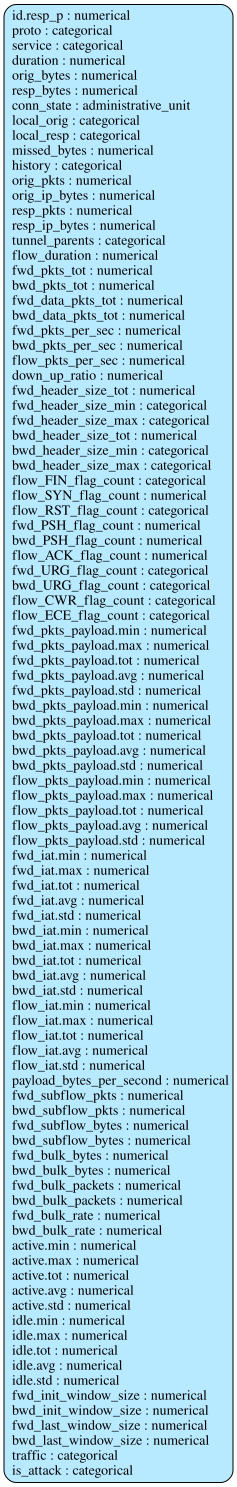

In [24]:
metadata.visualize()

In [25]:
# manually override the high-cardinality columns to be numerical
for col in numeric_cols:
    if col in gan_df.columns:
        metadata.update_column(column_name=col, sdtype='numerical')

In [26]:
from sdv.single_table import GaussianCopulaSynthesizer

def balance_dataset_GCS(df, target_column, target_size, metadata):
    counts = df[target_column].value_counts()
    minority_classes = counts[counts < target_size].index.tolist()
    
    synthetic_data_list = []
    
    for cls in minority_classes:
        print(f"Generating data for: {cls}")
        data_to_learn = df[df[target_column] == cls].copy()
        
        # FAST MODEL
        synthesizer = GaussianCopulaSynthesizer(metadata)
        synthesizer.fit(data_to_learn)
        
        num_needed = target_size - len(data_to_learn)
        synthetic_samples = synthesizer.sample(num_rows=num_needed)
        synthetic_data_list.append(synthetic_samples)
        print(f"Generated {num_needed} samples.")
        
    return pd.concat([df] + synthetic_data_list, ignore_index=True)

In [27]:
full_df_balanced = balance_dataset_GCS(gan_df, 'traffic', 250000, metadata)

Generating data for: MQTT_Flood


/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:183: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:139: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


Generated 117494 samples.
Generating data for: Port_Scanning


/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:183: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)


Generated 123300 samples.
Generating data for: ICMP_Flood


...

Generated 222542 samples.
Generating data for: Arp_Spoofing


/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:183: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)


Generated 247033 samples.
Generating data for: BotNet_DDOS


/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:183: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)


Generated 249936 samples.


Checks after synthesizer

In [28]:
full_df_balanced['traffic'].value_counts()

traffic
TCP_Flood        381765
UDP_Flood        296553
HTTP_Flood       265025
Normal           250000
Port_Scanning    250000
Arp_Spoofing     250000
ICMP_Flood       250000
MQTT_Flood       250000
BotNet_DDOS      250000
Name: count, dtype: int64

NameError: name 'high_skew_features' is not defined

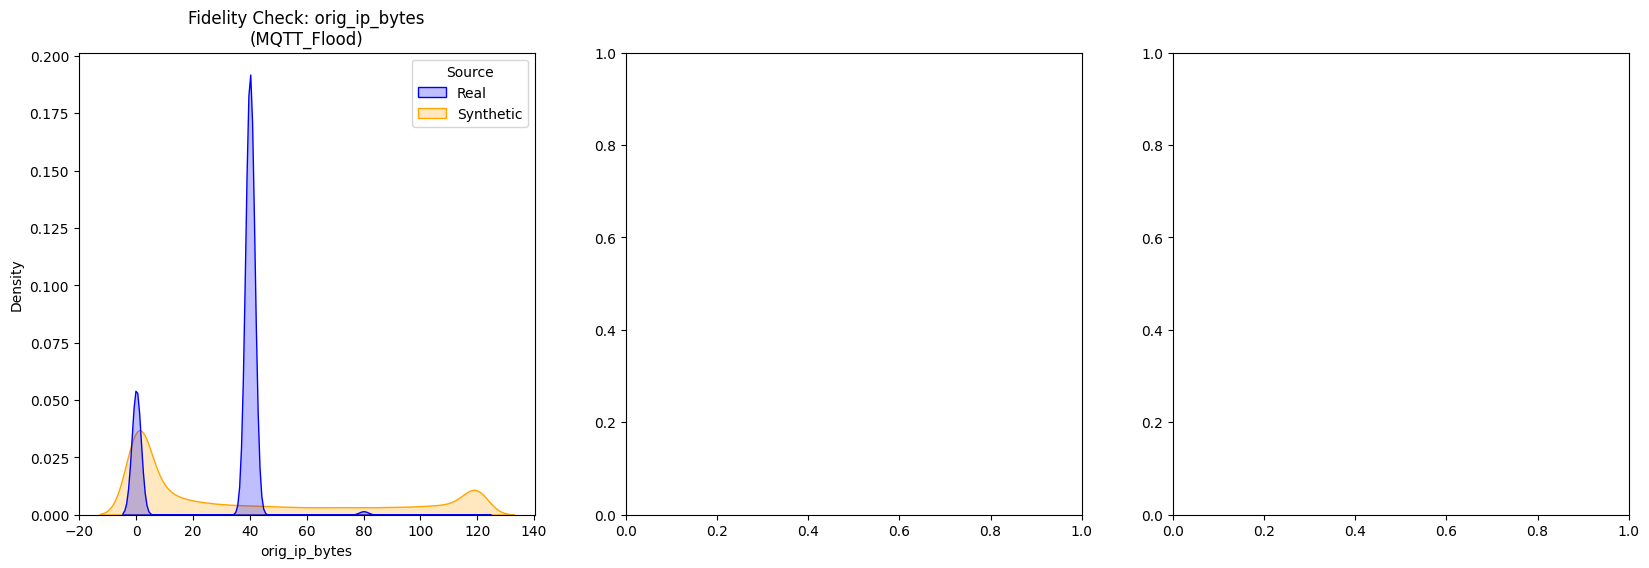

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

def compare_real_vs_synthetic(original_df, balanced_df, attack_type, features):
    # 1. Get the Real data for this attack
    real_data = original_df[original_df['traffic'] == attack_type].copy()
    real_data['Source'] = 'Real'
    
    # 2. Identify the Synthetic data 
    # Since balanced_df is original + synthetic, we isolate the new rows
    # A simple way is to take everything that wasn't in the original index
    total_class_data = balanced_df[balanced_df['traffic'] == attack_type].copy()
    
    # Slice to get only the synthetic part (the rows added beyond the original count)
    original_count = len(real_data)
    synthetic_data = total_class_data.iloc[original_count:].copy()
    synthetic_data['Source'] = 'Synthetic'
    
    # 3. Combine them for plotting
    comparison_df = pd.concat([real_data, synthetic_data])

    # 4. Plotting
    fig, axes = plt.subplots(1, len(features), figsize=(20, 6))
    
    for i, col in enumerate(features):
        # We overlay both KDEs
        sns.kdeplot(data=comparison_df, x=col, hue='Source', 
                    ax=axes[i], fill=True, common_norm=False, palette=['blue', 'orange'])
        
        axes[i].set_title(f'Fidelity Check: {col}\n({attack_type})')
        axes[i].set_xlabel('Log-Scaled Value' if col in high_skew_features else 'Value')

    plt.tight_layout()
    plt.show()

# Run the comparison for MQTT_Flood
important_features = ['orig_ip_bytes', 'resp_ip_bytes', 'fwd_iat.tot']
compare_real_vs_synthetic(full_df, full_df_balanced, 'MQTT_Flood', important_features)

**Preprocessing**

**Log-Transformation**

Extreme skewness in `flow_duration` and `payload_bytes` were found. Since Deep Learning uses gradient descent, large outliers can cause gradients to explode. we apply the transformation:

`log(x + 1)`

to all high-skew features.

In [30]:
num_cols = full_df_balanced.select_dtypes(include=['float64', 'int64']).columns.tolist()
if 'is_attack' in num_cols: num_cols.remove('is_attack')

# Calculate skewness
skewness = full_df_balanced[num_cols].skew().sort_values(ascending=False)

# Select features with skewness > 1.0
high_skew_features = skewness[abs(skewness) > 1.0].index.tolist()

print(f"Applying Log-Transformation to {len(high_skew_features)} skewed features...")

# Apply log1p (log(x+1)) to handle 0 values safely
for col in high_skew_features:
    full_df_balanced[col] = np.log1p(full_df_balanced[col])

Applying Log-Transformation to 81 skewed features...


In [31]:
full_df_balanced['service'] = full_df_balanced['service'].replace('-', 'unknown')
cat_cols = ['proto', 'service', 'conn_state']

# Perform One-Hot Encoding
full_df_balanced = pd.get_dummies(full_df_balanced, columns=cat_cols, prefix=cat_cols)

new_cat_cols = [c for c in full_df_balanced.columns if any(p in c for p in cat_cols)]
full_df_balanced[new_cat_cols] = full_df_balanced[new_cat_cols].astype(int)

print(f"One-Hot Encoding complete. New shape: {full_df_balanced.shape}")

One-Hot Encoding complete. New shape: (2443343, 169)


In [32]:
class NetworkTrafficGenerator(tf.keras.utils.Sequence):
    def __init__(self, x_data, y_data, indices, window_size, batch_size=1024):
        self.x_data = x_data
        self.y_data = y_data
        self.indices = indices
        self.window_size = window_size
        self.batch_size = batch_size

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, index):
        batch_indices = self.indices[index * self.batch_size : (index + 1) * self.batch_size]
        
        x_batch = []
        y_batch = []
        
        for idx in batch_indices:
            # Grab window of 10 from the 2D scaled matrix
            x_batch.append(self.x_data[idx : idx + self.window_size])
            # The label is the packet immediately following the window
            y_batch.append(self.y_data[idx + self.window_size])
            
        return np.array(x_batch, dtype='float32'), np.array(y_batch, dtype='int8')


In [33]:
from sklearn.preprocessing import LabelEncoder

WINDOW_SIZE = 10
# 1. DROP NON-TRAINING COLUMNS (IDs and Strings)
# We need to remove these BEFORE converting to float32
id_cols = ['id.orig_h', 'id.resp_h', 'history', 'tunnel_parents', 'id.orig_p']
full_df_balanced = full_df_balanced.drop(columns=[c for c in id_cols if c in full_df_balanced.columns], errors='ignore')

# 2. HANDLE 'T'/'F' OR REMAINING STRINGS
# This identifies columns that aren't numbers yet (like those containing 'T')
obj_cols = full_df_balanced.select_dtypes(include=['object']).columns.tolist()

# We remove 'traffic' from this list because we want to encode it separately as our target
if 'traffic' in obj_cols: 
    obj_cols.remove('traffic')

print(f"Cleaning {len(obj_cols)} remaining object columns...")
for col in obj_cols:
    # This turns 'T' into 1, 'F' into 0, and anything else into NaN, then fills with 0
    full_df_balanced[col] = pd.to_numeric(full_df_balanced[col], errors='coerce').fillna(0)

# 3. MULTI-CLASS LABEL ENCODING
# Encode the 'traffic' strings (TCP_Flood, Normal, etc.) into integers
le = LabelEncoder()
full_df_balanced['traffic_encoded'] = le.fit_transform(full_df_balanced['traffic'])
num_classes = len(le.classes_)

print(f"Target classes: {le.classes_}")

# 4. DEFINE X AND y
# We drop BOTH 'is_attack' and the 'traffic' strings. 
# We keep only numeric features for X.
X = full_df_balanced.drop(columns=['is_attack', 'traffic', 'traffic_encoded'], errors='ignore').astype('float32')
y = full_df_balanced['traffic_encoded'].values.astype('int32')

# 5. SCALE THE DATA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Normalization complete. X_scaled shape:", X_scaled.shape)

# 6. TRAIN/TEST SPLIT
indices = np.arange(len(X_scaled) - WINDOW_SIZE)
y_stratify = y[WINDOW_SIZE:]

train_idx, temp_idx = train_test_split(indices, test_size=0.3, 
                                       stratify=y_stratify, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, 
                                     stratify=y_stratify[temp_idx], random_state=42)

# 7. INITIALIZE GENERATORS
train_gen = NetworkTrafficGenerator(X_scaled, y, train_idx, WINDOW_SIZE)
val_gen = NetworkTrafficGenerator(X_scaled, y, val_idx, WINDOW_SIZE)
test_gen = NetworkTrafficGenerator(X_scaled, y, test_idx, WINDOW_SIZE)

Cleaning 2 remaining object columns...
Target classes: ['Arp_Spoofing' 'BotNet_DDOS' 'HTTP_Flood' 'ICMP_Flood' 'MQTT_Flood'
 'Normal' 'Port_Scanning' 'TCP_Flood' 'UDP_Flood']
Normalization complete. X_scaled shape: (2443343, 165)


**Training**


In [43]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd
import numpy as np

def plot_model_performance(y_true, y_pred, class_names, model_name="Model"):
    """
    Generates a Confusion Matrix Heatmap and a Metrics Bar Chart.
    """
    cm = confusion_matrix(y_true, y_pred)
    # Calculate percentages for the heatmap (Normalized CM)
    cm_perc = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    report_df = pd.DataFrame(report_dict).iloc[:-1, :len(class_names)].T # Extract F1, Precision, Recall

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1,
                xticklabels=class_names, yticklabels=class_names)
    ax1.set_title(f'Confusion Matrix (Counts): {model_name}')
    ax1.set_ylabel('Actual Traffic')
    ax1.set_xlabel('Predicted Traffic')

    report_df.plot(kind='bar', ax=ax2, color=['#3498db', '#e74c3c', '#2ecc71'])
    ax2.set_title(f'Per-Class Metrics: {model_name}')
    ax2.set_ylabel('Score (0.0 to 1.0)')
    ax2.set_ylim(0, 1.1)
    ax2.grid(axis='y', linestyle='--', alpha=0.7)
    plt.xticks(rotation=45)
    
    plt.tight_layout()
    plt.show()
    print(classification_report(y_true, y_pred, target_names=class_names))

**Defining the Peephole LSTM Architecture**
- Since Keras's default LSTM layer does not support Peephole connections (they were removed in newer versions for speed), we have to use the `LSTMCell` within an `RNN` layer to enable them.

**Custom Peephole Cell**

In a Peephole LSTM, the gates (`i`, `f`, `o`) use the cell state (`c`) to make their decisions. We will create a custom class that inherits from `tf.keras.layers.Layer`.

In [34]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define the Custom Peephole Cell
class PeepholeLSTMCell(layers.Layer):
    def __init__(self, units, **kwargs):
        self.units = units
        self.state_size = [units, units] # [hidden_state, cell_state]
        super(PeepholeLSTMCell, self).__init__(**kwargs)

    def build(self, input_shape):
        input_dim = input_shape[-1]
        
        # Standard weights for Input, Forget, and Output gates
        self.kernel = self.add_weight(shape=(input_dim, self.units * 4), name='kernel', initializer='glorot_uniform')
        self.recurrent_kernel = self.add_weight(shape=(self.units, self.units * 4), name='recurrent_kernel', initializer='orthogonal')
        self.bias = self.add_weight(shape=(self.units * 4,), name='bias', initializer='zeros')
        
        # THE PEEPHOLE WEIGHTS (V matrices)
        self.peephole_i = self.add_weight(shape=(self.units,), name='peephole_i', initializer='zeros')
        self.peephole_f = self.add_weight(shape=(self.units,), name='peephole_f', initializer='zeros')
        self.peephole_o = self.add_weight(shape=(self.units,), name='peephole_o', initializer='zeros')
        
        self.built = True

    def call(self, inputs, states):
        h_tm1, c_tm1 = states # States from previous time step

        # Compute Gates
        z = tf.matmul(inputs, self.kernel) + tf.matmul(h_tm1, self.recurrent_kernel) + self.bias
        z_i, z_f, z_c, z_o = tf.split(z, num_or_size_splits=4, axis=1)

        # Apply Peephole connections (gates see c_tm1)
        i = tf.sigmoid(z_i + self.peephole_i * c_tm1)
        f = tf.sigmoid(z_f + self.peephole_f * c_tm1)
        
        # Calculate new Cell State
        c = f * c_tm1 + i * tf.tanh(z_c)
        
        # Apply Peephole connection to Output gate (gate sees updated c)
        o = tf.sigmoid(z_o + self.peephole_o * c)
        
        # Final Hidden State
        h = o * tf.tanh(c)
        
        return h, [h, c]

# Get dimensions dynamically
n_features = X_scaled.shape[1]

# Build Model (using modern Keras Input layer)
model_peephole = models.Sequential([
    layers.Input(shape=(WINDOW_SIZE, n_features)),
    layers.RNN(PeepholeLSTMCell(64)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dense(num_classes, activation='softmax') 
])

model_peephole.compile(
    optimizer='adam', 
    loss='sparse_categorical_crossentropy', 
    metrics=['accuracy']
)

model_peephole.summary()

I0000 00:00:1786016761.771019      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rnn (RNN)                       │ (None, 64)             │        59,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,705 (241.04 KB)

 Trainable params: 61,577 (240.54 KB)

 Non-trainable params: 128 (512.00 B)

In [35]:
# Train using Generators
history_peephole = model_peephole.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5,  
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', 
            patience=2, 
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


  17/1671 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.3281 - loss: 2.0663

I0000 00:00:1786016775.139637     212 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1671/1671 ━━━━━━━━━━━━━━━━━━━━ 29s 14ms/step - accuracy: 0.9887 - loss: 0.0387 - val_accuracy: 0.9782 - val_loss: 0.0407
Epoch 2/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9964 - loss: 0.0102 - val_accuracy: 0.9973 - val_loss: 0.0067
Epoch 3/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.9968 - loss: 0.0081 - val_accuracy: 0.9972 - val_loss: 0.0073
Epoch 4/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.9969 - loss: 0.0079 - val_accuracy: 0.9967 - val_loss: 0.0073


358/358 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step


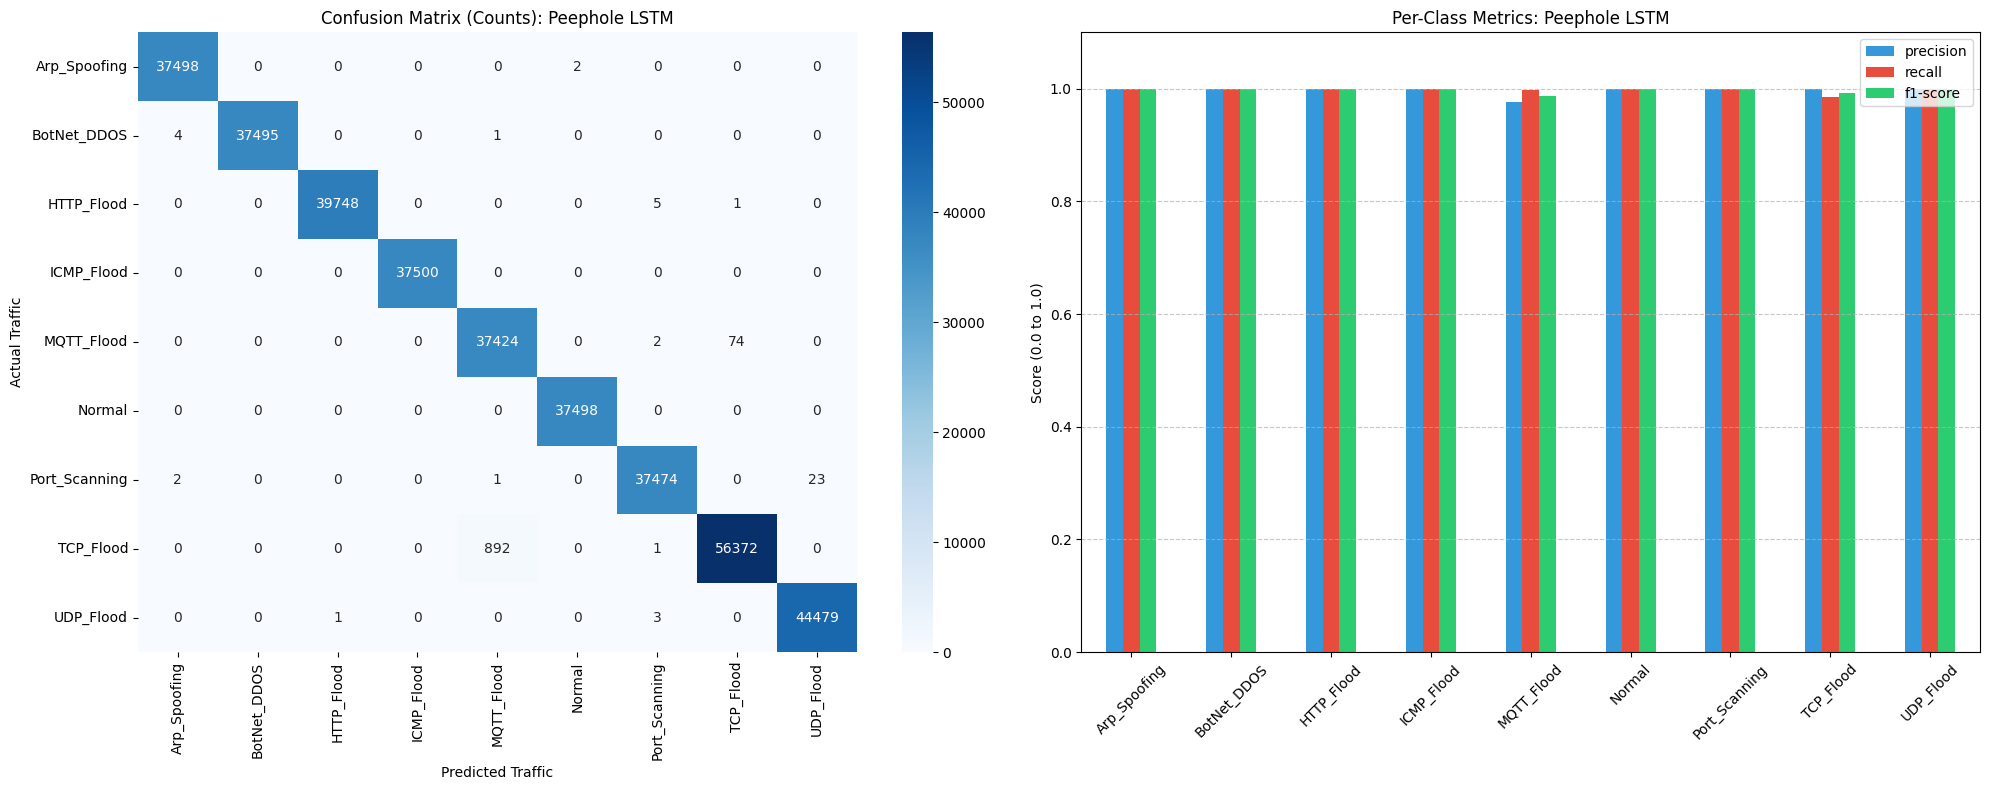

               precision    recall  f1-score   support

 Arp_Spoofing       1.00      1.00      1.00     37500
  BotNet_DDOS       1.00      1.00      1.00     37500
   HTTP_Flood       1.00      1.00      1.00     39754
   ICMP_Flood       1.00      1.00      1.00     37500
   MQTT_Flood       0.98      1.00      0.99     37500
       Normal       1.00      1.00      1.00     37498
Port_Scanning       1.00      1.00      1.00     37500
    TCP_Flood       1.00      0.98      0.99     57265
    UDP_Flood       1.00      1.00      1.00     44483

     accuracy                           1.00    366500
    macro avg       1.00      1.00      1.00    366500
 weighted avg       1.00      1.00      1.00    366500



In [44]:

y_pred_prob = model_peephole.predict(test_gen)
y_pred_lstm = np.argmax(y_pred_prob, axis=1)

# Pull the correct true labels for the test set
y_test_final = y[test_idx + WINDOW_SIZE]

# Visualize
plot_model_performance(y_test_final, y_pred_lstm, le.classes_, "Peephole LSTM")

**Minimal GRU**

In [36]:
# Define the Custom Minimal GRU Cell
class MinimalGRUCell(layers.Layer):
    def __init__(self, units, **kwargs):
        self.units = units
        self.state_size = units # Only hidden state, no cell state
        super(MinimalGRUCell, self).__init__(**kwargs)

    def build(self, input_shape):
        input_dim = input_shape[-1]
        
        # MGU has only ONE gate (f)
        # We need weights for the gate and the candidate state
        self.kernel = self.add_weight(shape=(input_dim, self.units * 2), 
                                      name='kernel',
                                      initializer='glorot_uniform')
        self.recurrent_kernel = self.add_weight(shape=(self.units, self.units * 2), 
                                                name='recurrent_kernel',
                                                initializer='orthogonal')
        self.bias = self.add_weight(shape=(self.units * 2,), 
                                    name='bias', 
                                    initializer='zeros')
        self.built = True

    def call(self, inputs, states):
        h_tm1 = states[0]
        
        # Linear transformations
        z = tf.matmul(inputs, self.kernel) + tf.matmul(h_tm1, self.recurrent_kernel) + self.bias
        z_f, z_h = tf.split(z, num_or_size_splits=2, axis=1)
        
        # The single gate: Forget/Update merged
        f = tf.sigmoid(z_f)
        
        # Candidate hidden state (Only the candidate uses the gate in MGU)
        h_tilde = tf.tanh(z_h * f) 
        
        # New hidden state: (1-f)*h_tm1 + f*h_tilde
        h = (1 - f) * h_tm1 + f * h_tilde
        return h, [h]

# Get dimensions dynamically
n_features = X_scaled.shape[1]

# Build Model (Memory-safe version)
model_mgu = models.Sequential([
    layers.Input(shape=(WINDOW_SIZE, n_features)),
    layers.RNN(MinimalGRUCell(64)),
    layers.BatchNormalization(),
    layers.Dense(32, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model_mgu.compile(
    optimizer='adam', 
    loss='sparse_categorical_crossentropy', 
    metrics=['accuracy']
)

model_mgu.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rnn_1 (RNN)                     │ (None, 64)             │        29,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,073 (125.29 KB)

 Trainable params: 31,945 (124.79 KB)

 Non-trainable params: 128 (512.00 B)

In [37]:
# Train the MGU
history_mgu = model_mgu.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', 
            patience=2, 
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.9888 - loss: 0.0389 - val_accuracy: 0.9961 - val_loss: 0.0088
Epoch 2/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9970 - loss: 0.0076 - val_accuracy: 0.9973 - val_loss: 0.0073
Epoch 3/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9967 - loss: 0.0083 - val_accuracy: 0.9974 - val_loss: 0.0064
Epoch 4/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.9972 - loss: 0.0070 - val_accuracy: 0.9974 - val_loss: 0.0068
Epoch 5/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9973 - loss: 0.0065 - val_accuracy: 0.9975 - val_loss: 0.0061


358/358 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step


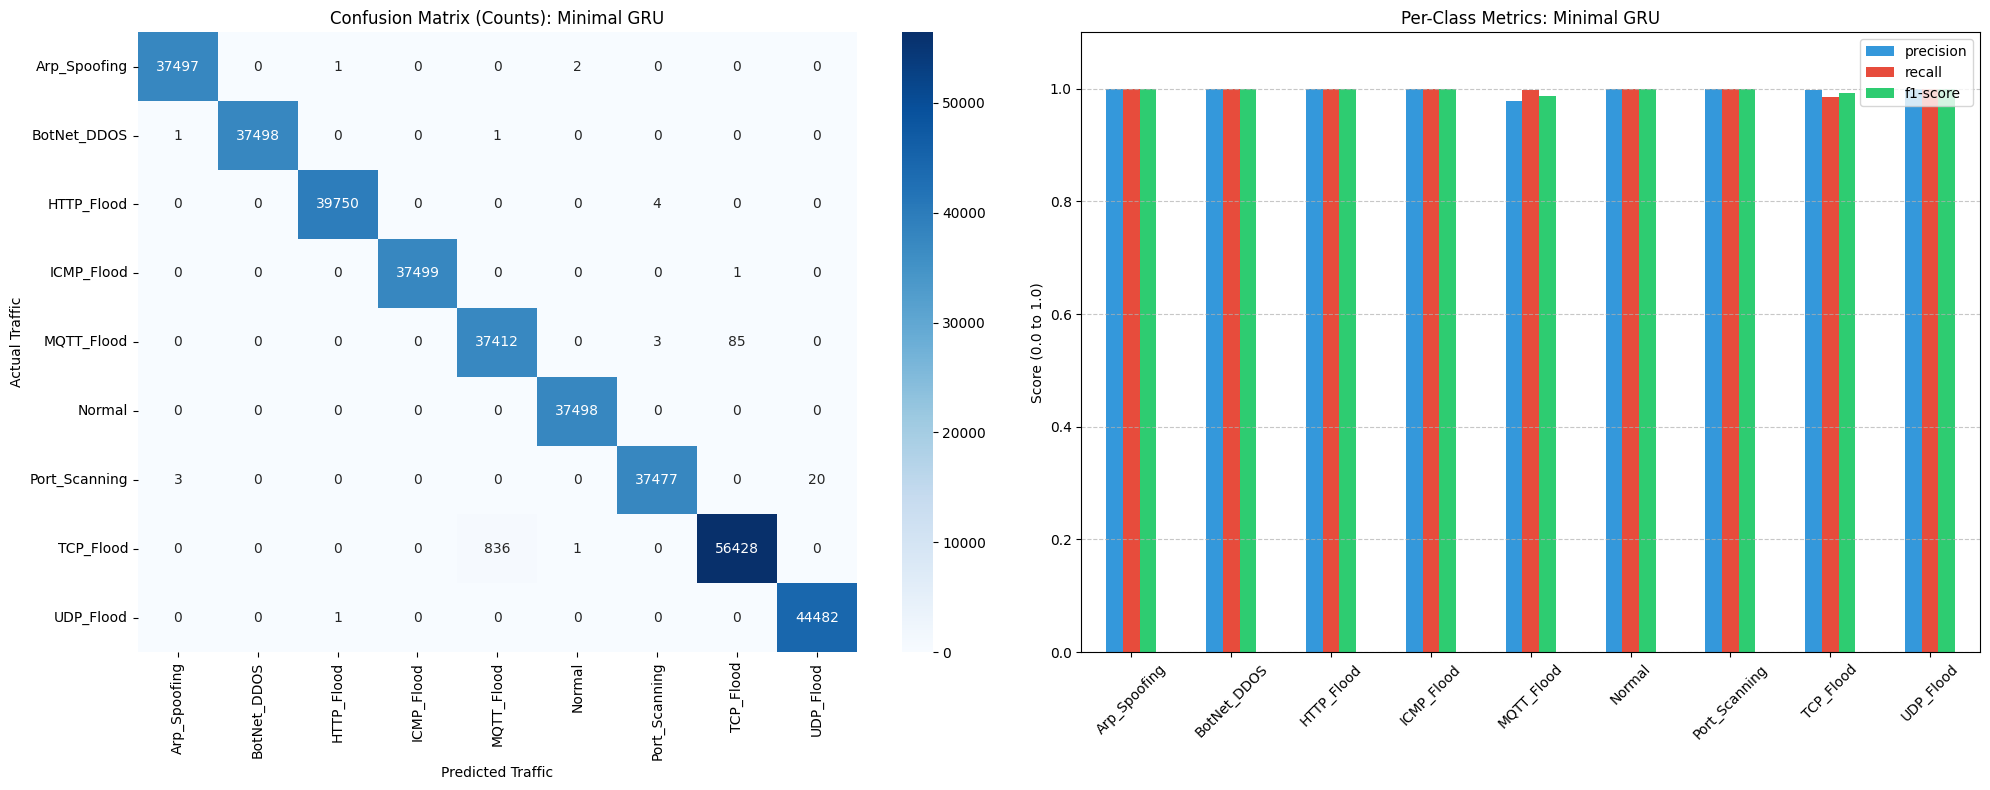

               precision    recall  f1-score   support

 Arp_Spoofing       1.00      1.00      1.00     37500
  BotNet_DDOS       1.00      1.00      1.00     37500
   HTTP_Flood       1.00      1.00      1.00     39754
   ICMP_Flood       1.00      1.00      1.00     37500
   MQTT_Flood       0.98      1.00      0.99     37500
       Normal       1.00      1.00      1.00     37498
Port_Scanning       1.00      1.00      1.00     37500
    TCP_Flood       1.00      0.99      0.99     57265
    UDP_Flood       1.00      1.00      1.00     44483

     accuracy                           1.00    366500
    macro avg       1.00      1.00      1.00    366500
 weighted avg       1.00      1.00      1.00    366500



In [46]:

y_pred_prob = model_mgu.predict(test_gen)
y_pred_lstm = np.argmax(y_pred_prob, axis=1)

# Pull the correct true labels for the test set
y_test_final = y[test_idx + WINDOW_SIZE]

# Visualize
plot_model_performance(y_test_final, y_pred_lstm, le.classes_, "Minimal GRU")

**Lightweight Transformer**

In [39]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Define the Transformer Encoder Block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    # Multi-Head Self-Attention
    x = layers.LayerNormalization(epsilon=1e-6)(inputs)
    x = layers.MultiHeadAttention(
        key_dim=head_size, num_heads=num_heads, dropout=dropout
    )(x, x)
    x = layers.Dropout(dropout)(x)
    res = x + inputs # Residual connection

    # Feed Forward Part
    x = layers.LayerNormalization(epsilon=1e-6)(res)
    x = layers.Conv1D(filters=ff_dim, kernel_size=1, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    # Project back to original feature dimension
    x = layers.Conv1D(filters=inputs.shape[-1], kernel_size=1)(x)
    return x + res

# 2. Build the Model
n_features = X_scaled.shape[1]
inputs = layers.Input(shape=(WINDOW_SIZE, n_features))

# Simple Positional Encoding
# Since we use a fixed WINDOW_SIZE=10, we give each position (0-9) a unique embedding
pos_indices = tf.range(start=0, limit=WINDOW_SIZE, delta=1)
pos_encoding = layers.Embedding(input_dim=WINDOW_SIZE, output_dim=n_features)(pos_indices)
x = inputs + pos_encoding

# One Transformer Block
x = transformer_encoder(x, head_size=64, num_heads=4, ff_dim=128, dropout=0.1)

# Global Average Pooling (aggregates the 10 packets into one feature vector)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation="relu")(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model_transformer = models.Model(inputs, outputs)

model_transformer.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_transformer.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 10, 165)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 10, 165)   │          0 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 165)   │        330 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 10, 165)   │    169,893 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 10, 165)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 10, 165)   │          0 │ dropout_6[0][0],  │
│                     │                   │            │ add_3[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 165)   │        330 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 10, 128)   │     21,248 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 10, 128)   │          0 │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 10, 165)   │     21,285 │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 10, 165)   │          0 │ conv1d_3[0][0],   │
│                     │                   │            │ add_4[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 165)       │          0 │ add_5[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 165)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 32)        │      5,312 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 9)         │        297 │ dense_6[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 218,695 (854.28 KB)

 Trainable params: 218,695 (854.28 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
# Train the Transformer
history_trans = model_transformer.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', 
            patience=2, 
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 42s 20ms/step - accuracy: 0.9936 - loss: 0.0199 - val_accuracy: 0.9974 - val_loss: 0.0065
Epoch 2/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 26s 16ms/step - accuracy: 0.9970 - loss: 0.0076 - val_accuracy: 0.9973 - val_loss: 0.0067
Epoch 3/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.9972 - loss: 0.0066 - val_accuracy: 0.9975 - val_loss: 0.0060
Epoch 4/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.9972 - loss: 0.0067 - val_accuracy: 0.9973 - val_loss: 0.0066
Epoch 5/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 27s 16ms/step - accuracy: 0.9974 - loss: 0.0063 - val_accuracy: 0.9975 - val_loss: 0.0059


358/358 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step


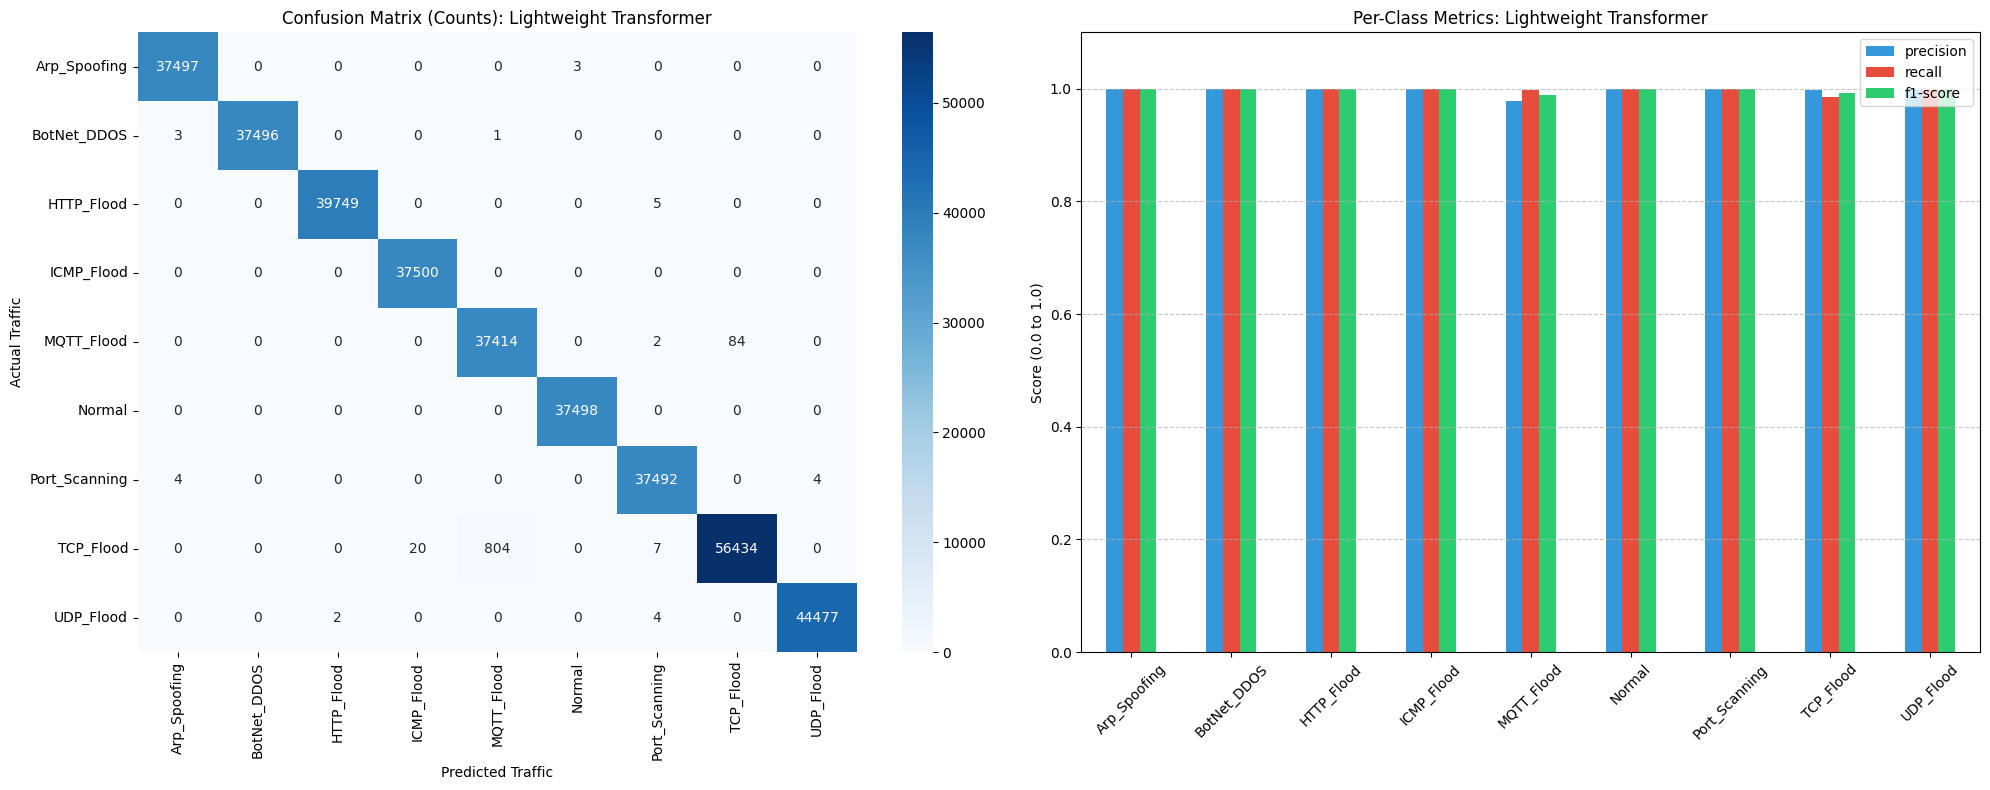

               precision    recall  f1-score   support

 Arp_Spoofing       1.00      1.00      1.00     37500
  BotNet_DDOS       1.00      1.00      1.00     37500
   HTTP_Flood       1.00      1.00      1.00     39754
   ICMP_Flood       1.00      1.00      1.00     37500
   MQTT_Flood       0.98      1.00      0.99     37500
       Normal       1.00      1.00      1.00     37498
Port_Scanning       1.00      1.00      1.00     37500
    TCP_Flood       1.00      0.99      0.99     57265
    UDP_Flood       1.00      1.00      1.00     44483

     accuracy                           1.00    366500
    macro avg       1.00      1.00      1.00    366500
 weighted avg       1.00      1.00      1.00    366500



In [47]:

y_pred_prob = model_transformer.predict(test_gen)
y_pred_lstm = np.argmax(y_pred_prob, axis=1)

# Pull the correct true labels for the test set
y_test_final = y[test_idx + WINDOW_SIZE]

# Visualize
plot_model_performance(y_test_final, y_pred_lstm, le.classes_, "Lightweight Transformer")

****Transformer-MGU Ensemble****

In [41]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Define Shared Input
n_features = X_scaled.shape[1]
ensemble_input = layers.Input(shape=(WINDOW_SIZE, n_features))

# BRANCH 1: Minimal GRU 
# We use 32 units here to balance the complexity between the two branches
mgu_branch = layers.RNN(MinimalGRUCell(32))(ensemble_input)
mgu_branch = layers.BatchNormalization()(mgu_branch)

# RANCH 2: Lightweight Transformer 
# Simple Positional Encoding
pos_indices = tf.range(start=0, limit=WINDOW_SIZE, delta=1)
pos_encoding = layers.Embedding(input_dim=WINDOW_SIZE, output_dim=n_features)(pos_indices)
trans_input = ensemble_input + pos_encoding

# Transformer Block with specific hyperparameters for the ensemble
trans_branch = transformer_encoder(
    trans_input, 
    head_size=32,   # Optimized for multi-branch balance
    num_heads=2, 
    ff_dim=64, 
    dropout=0.1
)
trans_branch = layers.GlobalAveragePooling1D()(trans_branch)
trans_branch = layers.BatchNormalization()(trans_branch)

# Concatenate the local sequential features with the global attention features
merged = layers.Concatenate()([mgu_branch, trans_branch])

# Final Decision Layers
x = layers.Dense(32, activation="relu")(merged)
x = layers.Dropout(0.2)(x)
ensemble_output = layers.Dense(num_classes, activation="softmax")(x)

# Create the Model
model_ensemble = models.Model(inputs=ensemble_input, outputs=ensemble_output)

model_ensemble.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_ensemble.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 10, 165)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 10, 165)   │          0 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 165)   │        330 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 10, 165)   │     42,597 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 10, 165)   │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (None, 10, 165)   │          0 │ dropout_10[0][0], │
│                     │                   │            │ add_6[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 165)   │        330 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 10, 64)    │     10,624 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 10, 64)    │          0 │ conv1d_4[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 10, 165)   │     10,725 │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 10, 165)   │          0 │ conv1d_5[0][0],   │
│                     │                   │            │ add_7[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rnn_2 (RNN)         │ (None, 32)        │     12,672 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 165)       │          0 │ add_8[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32)        │        128 │ rnn_2[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 165)       │        660 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 197)       │          0 │ batch_normalizat… │
│ (Concatenate)       │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 32)        │      6,336 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 32)        │          0 │ dense_8[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 84,699 (330.86 KB)

 Trainable params: 84,305 (329.32 KB)

 Non-trainable params: 394 (1.54 KB)

In [42]:
# Train the Ensemble
history_ensemble = model_ensemble.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', 
            patience=2, 
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 42s 18ms/step - accuracy: 0.9922 - loss: 0.0283 - val_accuracy: 0.9974 - val_loss: 0.0073
Epoch 2/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.9967 - loss: 0.0097 - val_accuracy: 0.9975 - val_loss: 0.0061
Epoch 3/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.9972 - loss: 0.0074 - val_accuracy: 0.9974 - val_loss: 0.0060
Epoch 4/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.9973 - loss: 0.0069 - val_accuracy: 0.9976 - val_loss: 0.0059
Epoch 5/5
1671/1671 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.9974 - loss: 0.0065 - val_accuracy: 0.9975 - val_loss: 0.0061


358/358 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step


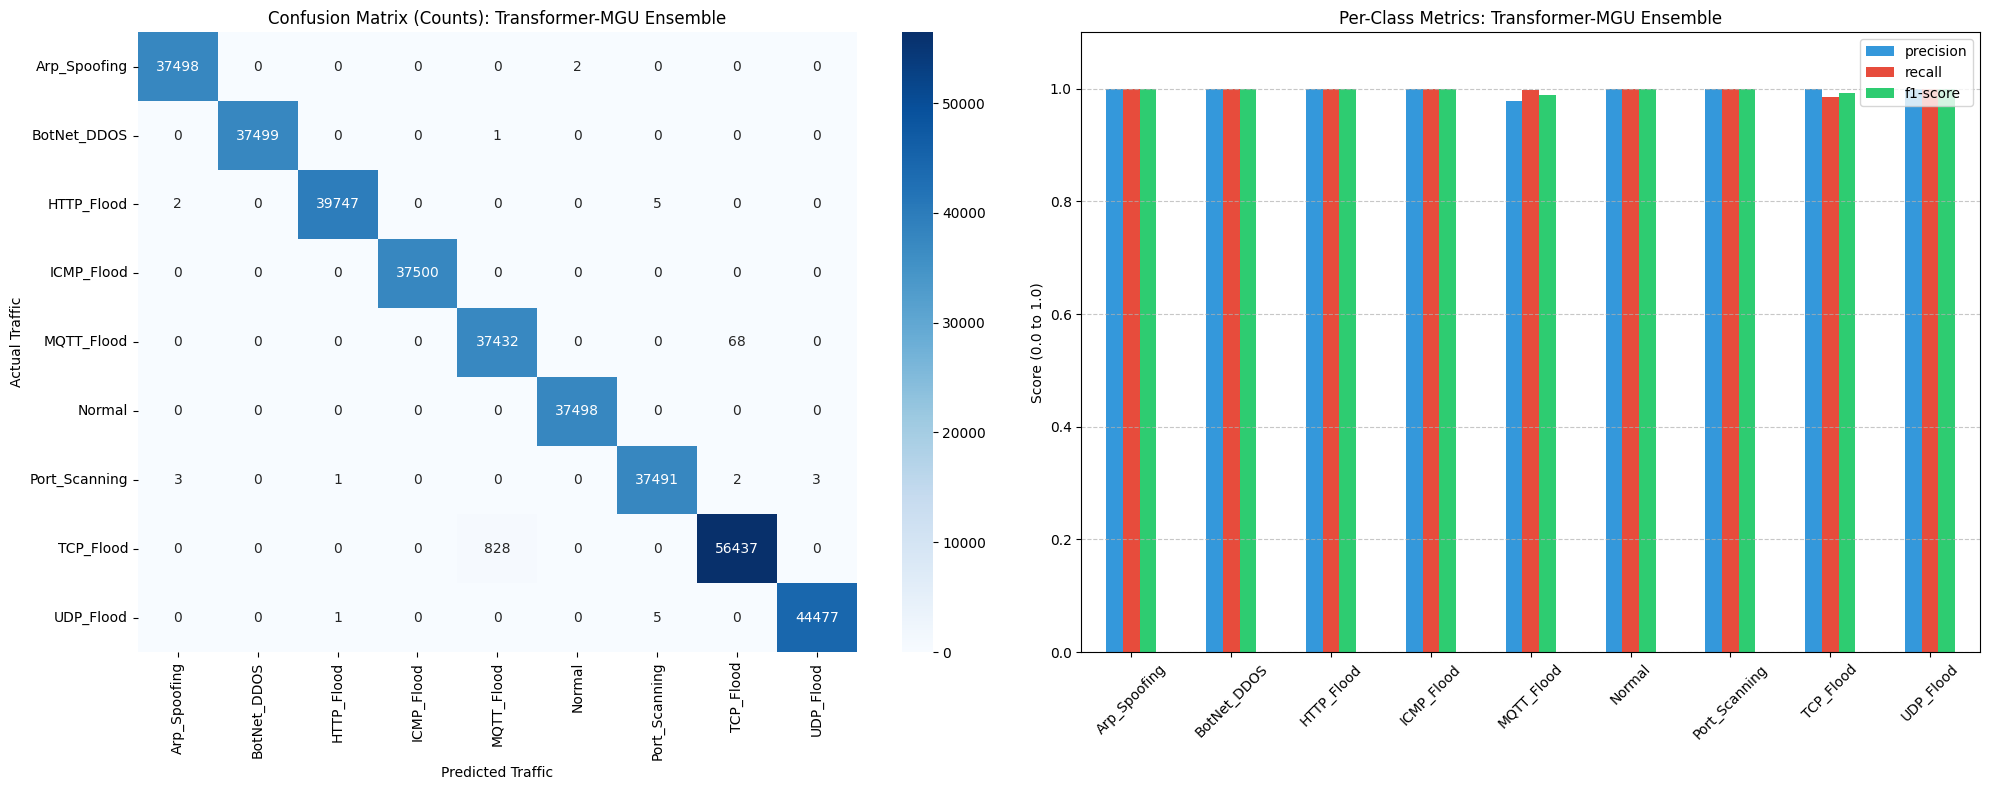

               precision    recall  f1-score   support

 Arp_Spoofing       1.00      1.00      1.00     37500
  BotNet_DDOS       1.00      1.00      1.00     37500
   HTTP_Flood       1.00      1.00      1.00     39754
   ICMP_Flood       1.00      1.00      1.00     37500
   MQTT_Flood       0.98      1.00      0.99     37500
       Normal       1.00      1.00      1.00     37498
Port_Scanning       1.00      1.00      1.00     37500
    TCP_Flood       1.00      0.99      0.99     57265
    UDP_Flood       1.00      1.00      1.00     44483

     accuracy                           1.00    366500
    macro avg       1.00      1.00      1.00    366500
 weighted avg       1.00      1.00      1.00    366500



In [48]:

y_pred_prob = model_ensemble.predict(test_gen)
y_pred_lstm = np.argmax(y_pred_prob, axis=1)

# Pull the correct true labels for the test set
y_test_final = y[test_idx + WINDOW_SIZE]

# Visualize
plot_model_performance(y_test_final, y_pred_lstm, le.classes_, "Transformer-MGU Ensemble")